# Warm-up: uncertainty-aware regression in one dimension

We regress
$$y = f(x) + \sigma(x)\,\varepsilon,\qquad
f(x) = \big(0.25 + 0.10\sqrt{1+x^2}\big)\,\sin(1.2x),\qquad \varepsilon \sim \mathcal{N}(0,1),$$
an oscillation whose **amplitude grows along the axis**, with noise
$$\sigma(x) = 0.04 + 0.10\big(1+\cos(0.9x)\big) + 0.25\,e^{-\frac{1}{2}\left(\frac{x-4.5}{0.7}\right)^2},$$
i.e. an oscillating noise floor plus one **localised noisy region** around $x \approx 4.5$. Training data exists only in $|x| < 6$, minus an interior **gap** $x \in [-0.5, 2.0]$. That gives *two different kinds of missing data*, deliberately:

- the **gap** tests *interpolation*: data on both sides, smoothness constrains the middle;
- the **sidebands** $|x| > 6$ test *extrapolation*: nothing constrains the function at all, and the honest answer is "I revert to my prior" — watch which methods actually say that.

The target of the exercise is estimating  $\sigma(x)$ → **aleatoric** with analytic ground truth (can the net find the noisy bump?)

Check gap and sidebands → **epistemic**, in its two flavours; the oscillation continues where data doesn't → confident extrapolations are *visibly* wrong.

Every method produces a band over $x$: we can use the metrics we discussed in the lesson to evaluate the quality of the model. 


## 0. Setup and data

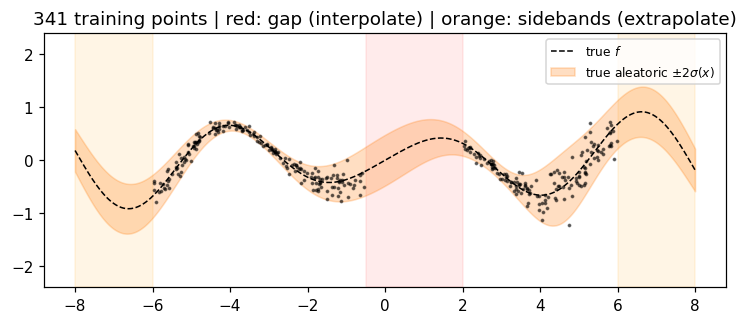

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

rng = np.random.default_rng(0)
torch.manual_seed(0)
plt.rcParams["figure.figsize"] = (8, 3); plt.rcParams["figure.dpi"] = 110

f_true     = lambda x: (0.25 + 0.10 * np.sqrt(1 + x**2)) * np.sin(1.2 * x)
sigma_true = lambda x: 0.04 + 0.10 * (1 + np.cos(0.9 * x)) + 0.25 * np.exp(-0.5 * ((x - 4.5) / 0.7) ** 2)
GAP  = (-0.5, 2.0)      # interior gap: interpolation test
SIDE = 6.0              # training exists only for |x| < SIDE: extrapolation test beyond

def simulate(n, rng, with_gap=True, lo=-8.0, hi=8.0):
    """with_gap=True applies the TRAINING selection (|x|<SIDE, outside the gap);
    with_gap=False is the full test range."""
    x = rng.uniform(lo, hi, n)
    if with_gap:
        x = x[(np.abs(x) < SIDE) & ((x < GAP[0]) | (x > GAP[1]))]
    y = f_true(x) + sigma_true(x) * rng.standard_normal(x.size)
    return x.astype(np.float32), y.astype(np.float32)

x_tr, y_tr = simulate(600, rng)                 # ~360 points after the selection: sparse on purpose
x_te, y_te = simulate(6000, rng, with_gap=False)
xg = np.linspace(-8, 8, 500, dtype=np.float32)  # dense grid for band plots

def shade_regions(ax):
    ax.axvspan(*GAP, color="r", alpha=0.08)                 # interpolation gap
    ax.axvspan(-8, -SIDE, color="orange", alpha=0.10)        # extrapolation sidebands
    ax.axvspan(SIDE, 8, color="orange", alpha=0.10)

def base_plot(ax=None):
    ax = ax or plt.gca()
    ax.plot(xg, f_true(xg), "k--", lw=1, label="true $f$")
    ax.plot(x_tr, y_tr, "k.", ms=3, alpha=0.5)
    shade_regions(ax)
    ax.set_ylim(-2.4, 2.4)
    return ax

ax = base_plot()
ax.fill_between(xg, f_true(xg) - 2*sigma_true(xg), f_true(xg) + 2*sigma_true(xg),
                color="C1", alpha=0.25, label=r"true aleatoric $\pm2\sigma(x)$")
ax.legend(fontsize=8)
ax.set_title(f"{len(x_tr)} training points | red: gap (interpolate) | orange: sidebands (extrapolate)");

## 1. The toolbox

Every method will expose itself as **predictive samples** of shape `(n_points, S)`.

Bands come from sample quantiles; metrics from the same arrays.

In [2]:
def pit_values(y, samples):
    return (samples < y[:, None]).mean(axis=1)

def central_coverage(y, samples, level):
    a = (1 - level) / 2
    lo, hi = np.quantile(samples, a, axis=1), np.quantile(samples, 1 - a, axis=1)
    return np.mean((y >= lo) & (y <= hi)), np.mean(hi - lo)

def crps_from_samples(y, samples):
    """CRPS from a sample-based predictive, averaged over events.

    Energy form of the CRPS (Gneiting & Raftery):

        CRPS(F, y) = E|X - y| - 1/2 E|X - X'|,     X, X' ~ F independent

    y       : (N,)   true values
    samples : (N, S) S predictive samples per event
              (ensemble members, MC-dropout passes, flow draws, ...)
    """
    # ---- term 1: E|X - y| -- accuracy of the cloud against the truth -------
    # Broadcast y against the S samples of its own event; plain MAE per event.
    # Alone it would reward sigma -> 0 (a point mass at the median wins).
    t1 = np.abs(samples - y[:, None]).mean(axis=1)

    # ---- term 2: E|X - X'| -- the "honesty refund" for internal spread -----
    # Naively (1/S^2) * sum_{j,k} |x_j - x_k|: an O(S^2) double sum.
    # THE TRICK: sort the samples. In the sum of all pairwise distances the
    # k-th smallest sample x_(k) appears
    #     +x_(k) against the (k-1) samples below it,
    #     -x_(k) against the (S-k) samples above it,
    # so its net coefficient is (k-1) - (S-k) = 2k - S - 1, and
    #
    #     sum_{j,k} |x_j - x_k| = 2 * sum_k (2k - S - 1) * x_(k)
    #
    # which is O(S log S) for the sort instead of O(S^2).
    # (This weighted sum of order statistics is the Gini mean difference.)
    s = np.sort(samples, axis=1)
    S = samples.shape[1]
    k = np.arange(1, S + 1)                       # 1-based rank
    t2 = (2.0 / S**2) * ((2 * k - S - 1) * s).sum(axis=1)

    # Note: the 1/S^2 keeps the j = k zero terms, slightly biasing CRPS up
    # for small S; the "fair CRPS" (Ferro) uses 1/(S*(S-1)) instead.
    return float((t1 - 0.5 * t2).mean())

def scoreboard(y, methods, levels=(0.68, 0.95)):
    print(f"{'method':<18}{'CRPS':>9}" + "".join(f"{'cov'+str(int(l*100)):>8}{'width'+str(int(l*100)):>9}" for l in levels))
    for name, s in methods.items():
        row = f"{name:<18}{crps_from_samples(y, s):>9.4f}"
        for l in levels:
            c, w = central_coverage(y, s, l)
            row += f"{c:>8.3f}{w:>9.4f}"
        print(row)

def band_plot(samples_grid, title, ax=None, color="C0"):
    '''samples_grid: (len(xg), S) predictive samples on the dense grid.'''
    ax = base_plot(ax)
    m  = samples_grid.mean(axis=1)
    lo, hi = np.quantile(samples_grid, 0.025, axis=1), np.quantile(samples_grid, 0.975, axis=1)
    ax.plot(xg, m, color=color, lw=1.4)
    ax.fill_between(xg, lo, hi, color=color, alpha=0.25)
    ax.set_title(title, fontsize=9)
    return ax

def decomposition_plot(mus, sigs, title, ax=None):
    '''Split the predictive uncertainty into its aleatoric and epistemic parts, as a function of x.

    Each member m (ensemble net, dropout pass, weight draw) predicts a Gaussian N(mu_m(x), sigma_m(x)^2).
    The prediction of the method is the MIXTURE of these M Gaussians. Law of total variance:

        Var[y] = E_m[sigma_m^2]  +  Var_m[mu_m]
                 \_ aleatoric _/    \_ epistemic _/

    mus, sigs : (M, len(xg)) Gaussian parameters of the M members on the dense grid xg
                (row = member, column = grid point)
    title     : title of the panel
    ax        : matplotlib axis; the current axis if None
    '''
    ax = ax or plt.gca()

    # ALEATORIC: the noise that the members predict, averaged over the members.
    # Average the VARIANCES (sigma^2), not the sigmas, then take the root to get a std.
    # .mean(0) averages over axis 0 = over the members, so one value per grid point remains.
    ax.plot(xg, np.sqrt((sigs ** 2).mean(0)), label=r"aleatoric $\sqrt{\mathbb{E}_m \sigma_m^2}$")

    # EPISTEMIC: the disagreement between the members about the mean.
    # .std(0) is the spread of mu_m over the members, at each grid point.
    # It is small where the data constrain the function and should be large where they do not.
    ax.plot(xg, mus.std(0), label=r"epistemic $\mathrm{std}_m\,\mu_m$")

    # REFERENCE: the true noise sigma(x) of the simulation.
    # Compare it with the ALEATORIC curve only. The epistemic curve has no analytic truth here.
    ax.plot(xg, sigma_true(xg), "k--", lw=0.8, label=r"true $\sigma(x)$")

    # Red band: the gap (interpolation). Orange bands: the sidebands (extrapolation).
    shade_regions(ax); ax.legend(fontsize=8)
    ax.set_title(title, fontsize=9)
    return ax   # return the axis, so the caller can add more curves


METHODS = {}       # name -> samples on x_te (for the scoreboard)
BANDS   = {}       # name -> samples on xg   (for the pictures)

## 2. Deterministic MLP: the failure mode

A plain MSE network draws one confident line — including straight through the gap, where it invents *some* interpolation of its own. Keep this picture; every following method is judged against it.

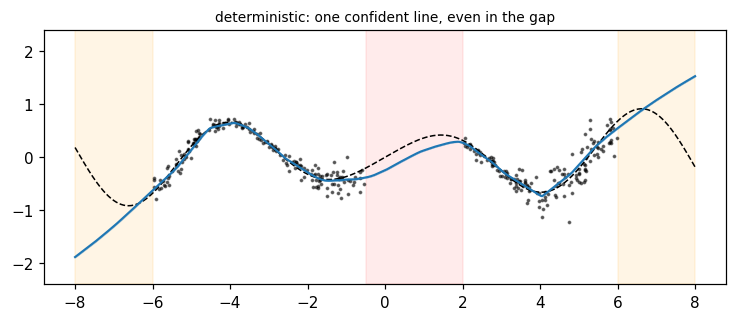

In [3]:
def mlp(n_in, n_out, hidden=64, depth=3, dropout=0.0):
    layers, d = [], n_in
    for _ in range(depth):
        layers += [nn.Linear(d, hidden), nn.ReLU()]
        if dropout > 0: layers += [nn.Dropout(dropout)]
        d = hidden
    return nn.Sequential(*(layers + [nn.Linear(d, n_out)]))

def train(model, loss_fn, x, y, epochs=400, lr=1e-3, batch=64, seed=0, weight_decay=1e-4):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    x, y = torch.as_tensor(x)[:, None], torch.as_tensor(y)
    for ep in range(epochs):
        perm = torch.randperm(x.shape[0])
        for i in range(0, x.shape[0], batch):
            idx = perm[i:i + batch]
            opt.zero_grad() 
            loss_fn(model(x[idx]), y[idx]).backward()
            opt.step()
    return model

mse = lambda out, y: ((out.squeeze(-1) - y) ** 2).mean()
det = train(mlp(1, 1), mse, x_tr, y_tr)

def det_samples(model, x):
    with torch.no_grad():
        mu = model(torch.as_tensor(x)[:, None]).squeeze(-1).numpy()
    return mu[:, None] + 1e-4 * rng.standard_normal((len(mu), 200))   # point mass, tiny width

METHODS["deterministic"] = det_samples(det, x_te)
BANDS["deterministic"]   = det_samples(det, xg)
band_plot(BANDS["deterministic"], "deterministic: one confident line, even in the gap");

## 3. Aleatoric: heteroscedastic Gaussian head 

Output $(\mu(x), \sigma(x))$, train with the (β-)Gaussian NLL — a proper score, which is *why* $\sigma$ converges to the truth. The payoff plot: learned $\sigma(x)$ over the analytic $\sigma(x)$.

Watch two things: it nails the noise where data exists, and it **stays confident in the gap** — the network has no notion of "I have never seen this $x$". Aleatoric $\neq$ epistemic.

In [4]:
def gauss_nll(out, y, beta=0.5):
    mu, log_s = out[:, 0], out[:, 1]
    # softplus is used to keep the log_sig positive
    sig = nn.functional.softplus(log_s) + 1e-4
    nll = 0.5 * ((y - mu) / sig) ** 2 + torch.log(sig)
    if beta > 0: nll = nll * sig.detach() ** (2 * beta)
    return nll.mean()

def hetero_predict(model, x):
    with torch.no_grad():
        out = model(torch.as_tensor(x)[:, None])
    return out[:, 0].numpy(), nn.functional.softplus(out[:, 1]).numpy() + 1e-4

def gaussian_samples(mu, sig, S=400):
    return mu[:, None] + sig[:, None] * rng.standard_normal((mu.size, S))

het = train(mlp(1, 2), gauss_nll, x_tr, y_tr)
METHODS["heteroscedastic"] = gaussian_samples(*hetero_predict(het, x_te))
BANDS["heteroscedastic"]   = gaussian_samples(*hetero_predict(het, xg))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
band_plot(BANDS["heteroscedastic"], "heteroscedastic: noise learned, gap still confident", ax=ax[0])
ax[1].plot(xg, sigma_true(xg), "k--", label=r"true $\sigma(x)$")
ax[1].plot(xg, hetero_predict(het, xg)[1], "C0", label=r"learned $\sigma(x)$")
ax[1].axvspan(*GAP, color="r", alpha=0.08); ax[1].legend(); ax[1].set_title("aleatoric ground-truth check")
plt.tight_layout()

## 4. Epistemic I: MC dropout

Let's train with `dropout=0.1`, keep dropout on at test time, average $T$ stochastic passes; combine with the heteroscedastic head (each pass draws from its own Gaussian). 

Plot the band: does the epistemic uncertainty increase in the gap?
Does the width depend on how much data you have? 
(Retrain with $3\times$ the data and compare)

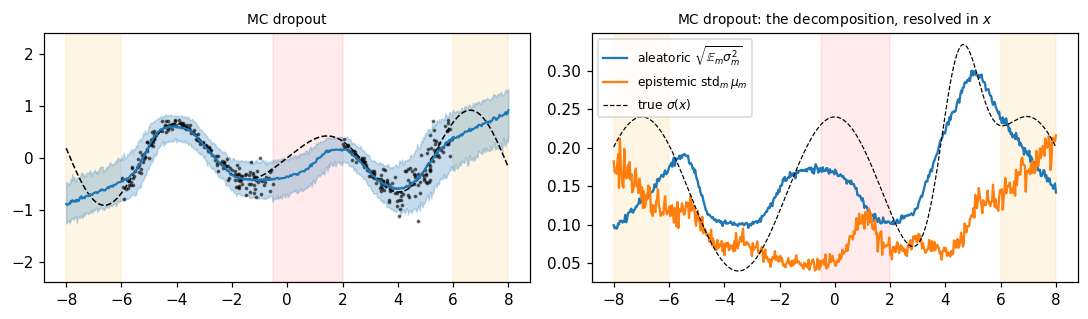

In [13]:
drop = train(mlp(1, 2, dropout=0.1), gauss_nll, x_tr, y_tr)

def mc_dropout_samples(model, x, T=100, draws_per_pass=4):
    model.train()
    out, mus, sigs = [], [], []
    with torch.no_grad():
        for _ in range(T):
            o = model(torch.as_tensor(x)[:, None])
            mu = o[:, 0].numpy(); sig = nn.functional.softplus(o[:, 1]).numpy() + 1e-4
            mus.append(mu); sigs.append(sig)
            out.append(mu[:, None] + sig[:, None] * rng.standard_normal((len(mu), draws_per_pass)))
    model.eval()
    return np.concatenate(out, axis=1), np.stack(mus), np.stack(sigs)

METHODS["MC dropout"], _, _ = mc_dropout_samples(drop, x_te)
BANDS["MC dropout"], mus_d, sigs_d = mc_dropout_samples(drop, xg)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
band_plot(BANDS["MC dropout"], "MC dropout", ax=ax[0])
decomposition_plot(mus_d, sigs_d, "MC dropout: the decomposition, resolved in $x$", ax=ax[1])
plt.tight_layout()

## 5. Epistemic II: deep ensemble

**EXERCISE:** train $M=5$ heteroscedastic nets from different seeds, pool their samples (a mixture — never average $\mu,\sigma$!). Then split the band into its two pieces with the decomposition
$\mathrm{Var}[y] = \mathbb{E}_m[\sigma_m^2] + \mathrm{Var}_m[\mu_m]$ and plot both vs $x$: which piece lights up in the gap, and which follows $\sigma(x)$?

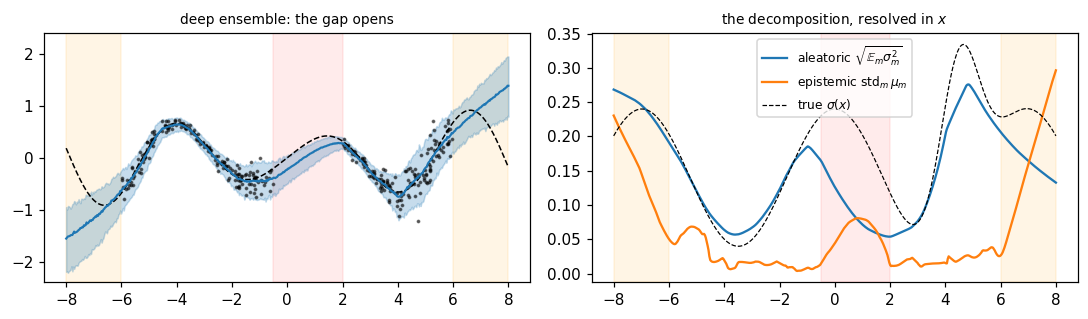

In [8]:
members = [train(mlp(1, 2), gauss_nll, x_tr, y_tr, seed=m) for m in range(5)]

def ens(x):
    mus, sigs = zip(*[hetero_predict(m, x) for m in members])
    mus, sigs = np.stack(mus), np.stack(sigs)
    S = np.concatenate([gaussian_samples(mus[m], sigs[m], S=80) for m in range(len(members))], axis=1)
    return S, mus, sigs

METHODS["deep ensemble"], _, _ = ens(x_te)
BANDS["deep ensemble"], mus_g, sigs_g = ens(xg)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
band_plot(BANDS["deep ensemble"], "deep ensemble: the gap opens", ax=ax[0])
decomposition_plot(mus_g, sigs_g, "the decomposition, resolved in $x$", ax=ax[1])
plt.tight_layout()

**EXERCISE**:  
1) Increase the amount of ensemble members:  how the uncertainties change?

## 5b. The defining experiment: epistemic shrinks with data, aleatoric does not

Everything in the lecture rests on one distinction: **epistemic uncertainty is reducible** (more data $\to$ tighter posterior $\to$ members agree) while **aleatoric is not** (it is a property of $p(y|x)$ itself).

Train the ensemble at $N = 50, 100, 300, 3000$ and watch:

- in the **sidebands**, the ensemble fan is huge at small $N$ and shrinks with data — but only because the learned functions pivot on better-constrained interior points; nothing ever anchors the extrapolation itself;
- in the **trained region**, the spread is small already at $N=100$ and then stops shrinking: it has hit the **optimization-noise floor**. Ensemble spread is posterior width *plus* training noise (init, bootstrap, SGD), and once the posterior contracts below that floor, more data stops helping. This is the fine print of "ensembles approximate the posterior";
- absolute spreads also track the local amplitude of $f$ — small in the gap, large in the sidebands — so compare regions with care;
- the **aleatoric** curve converge to the true $\sigma(x)$ and then *stop changing* — it was never about how much data you have;
- **MC dropout's** scale is set by the dropout rate, so whatever $N$-dependence 

Each member here is trained on a **bootstrap resample** of the data (bagging), so the spread includes the sampling variability of the dataset itself — this is what makes the $N$-scaling clean.

**Additional exercises**:
1. rerun *without* the bootstrap (all members on the identical dataset) and at $N=100$ the epistemic spread *collapses*  five networks underfitting the same 100 points agree on the same too-smooth curve. 

2. measure the floor directly — at $N=3000$, retrain the ensemble on the *identical* dataset (no bootstrap) and compare its trained-region spread to the bootstrapped one; the difference is sampling variability, the remainder is pure optimization noise.

     N  epi (trained)  epi (gap)  epi (sidebands)  dropout (trained)
    50         0.0744     0.2700           0.4388             0.1364
   100         0.0377     0.0237           0.3352             0.1464
   300         0.0469     0.0831           0.1109             0.1170
  3000         0.0377     0.0422           0.1191             0.0634


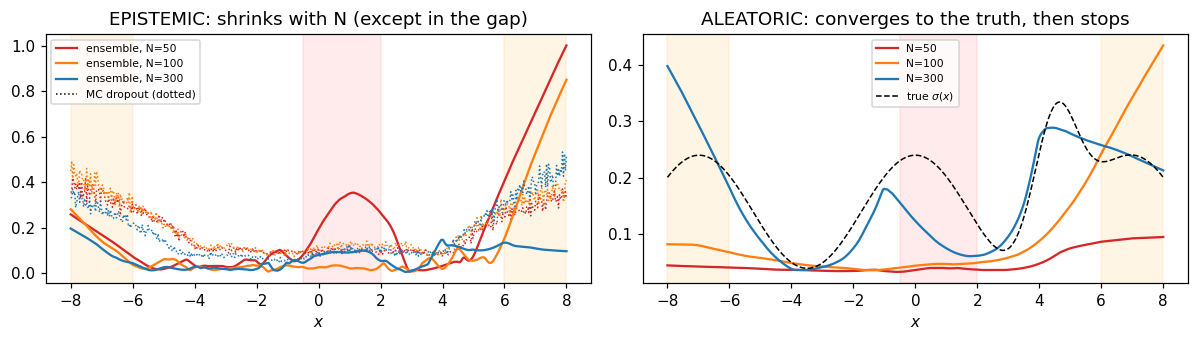

In [10]:
# === SOLUTION ===
Ns = [50, 100, 300, 3000]
res = {}
for N in Ns:
    xN, yN = simulate(N, np.random.default_rng(N))
    boots = [np.random.default_rng(100 * N + m).integers(0, len(xN), len(xN)) for m in range(5)]
    mem = [train(mlp(1, 2), gauss_nll, xN[b], yN[b], seed=m) for m, b in zip(range(5), boots)]
    mus_g, sigs_g = zip(*[hetero_predict(m, xg) for m in mem])
    mus_g, sigs_g = np.stack(mus_g), np.stack(sigs_g)
    dropN = train(mlp(1, 2, dropout=0.1), gauss_nll, xN, yN)
    dropN.train()
    with torch.no_grad():
        mu_dp = np.stack([dropN(torch.as_tensor(xg)[:, None])[:, 0].numpy() for _ in range(100)])
    dropN.eval()
    res[N] = dict(epi=mus_g.std(0), ale=np.sqrt((sigs_g ** 2).mean(0)), epi_drop=mu_dp.std(0))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
for N, c in zip(Ns, ["C3", "C1", "C0"]):
    ax[0].plot(xg, res[N]["epi"], c, label=f"ensemble, N={N}")
    ax[0].plot(xg, res[N]["epi_drop"], c, ls=":", lw=1)
    ax[1].plot(xg, res[N]["ale"], c, label=f"N={N}")
ax[0].plot([], [], "k:", lw=1, label="MC dropout (dotted)")
ax[1].plot(xg, sigma_true(xg), "k--", lw=1, label=r"true $\sigma(x)$")
for a, t in zip(ax, ["EPISTEMIC: shrinks with N (except in the gap)",
                     "ALEATORIC: converges to the truth, then stops"]):
    shade_regions(a); a.set(xlabel="$x$", title=t); a.legend(fontsize=7)
plt.tight_layout()

gap_m = (xg > GAP[0]) & (xg < GAP[1])
side_m = np.abs(xg) > SIDE
trained_m = (~gap_m) & (~side_m)
print(f"{'N':>6}{'epi (trained)':>15}{'epi (gap)':>11}{'epi (sidebands)':>17}{'dropout (trained)':>19}")
for N in Ns:
    print(f"{N:>6}{res[N]['epi'][trained_m].mean():>15.4f}{res[N]['epi'][gap_m].mean():>11.4f}"
          f"{res[N]['epi'][side_m].mean():>17.4f}{res[N]['epi_drop'][trained_m].mean():>19.4f}")

## 6. Epistemic III: a variational BNN from scratch (Bayes by Backprop)

Now the real thing: a **distribution over the weights**, learned by variational inference.
Each layer keeps $(\mu_j, \rho_j)$ per weight, $\sigma_j = \mathrm{softplus}(\rho_j)$, and every forward pass draws
$$w = \mu + \sigma \odot \varepsilon,\qquad \varepsilon \sim \mathcal{N}(0, I)$$
(the **reparameterisation trick**: sampling stays differentiable w.r.t. $\mu, \sigma$). Training maximises the ELBO
$$\mathcal{L} = \underbrace{\mathbb{E}_{q}\big[\log p(\mathcal{D} \mid w)\big]}_{\text{fit the data (noisy net)}} - \underbrace{\mathrm{KL}\big(q \,\|\, p(w)\big)}_{\text{stay close to the prior}},$$
which is "loss + weight decay" with one crucial change: the fit term is an expectation over a *noisy* network, so weights the data does not constrain keep a large $\sigma_j$ — the network **learns which of its own parameters it is uncertain about**.


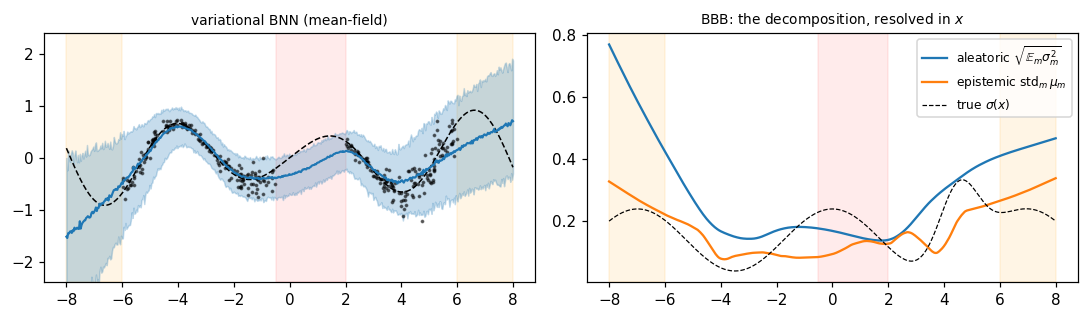

In [6]:
class BayesianLinear(nn.Module):
    """Linear layer with a factorised Gaussian q(w) = N(mu, sigma^2) per weight/bias."""
    def __init__(self, n_in, n_out, prior_std=1.0):
        super().__init__()
        self.w_mu  = nn.Parameter(0.1 * torch.randn(n_out, n_in))
        self.w_rho = nn.Parameter(torch.full((n_out, n_in), -5.0))   # sigma = softplus(rho) ~ 0.007 at init
        self.b_mu  = nn.Parameter(torch.zeros(n_out))
        self.b_rho = nn.Parameter(torch.full((n_out,), -5.0))
        self.prior_std = prior_std

    def sigmas(self):
        return nn.functional.softplus(self.w_rho), nn.functional.softplus(self.b_rho)

    def forward(self, x, sample=True):
        w_s, b_s = self.sigmas()
        if sample:                                   # reparameterisation trick
            w = self.w_mu + w_s * torch.randn_like(w_s)
            b = self.b_mu + b_s * torch.randn_like(b_s)
        else:
            w, b = self.w_mu, self.b_mu
        return nn.functional.linear(x, w, b)

    def kl(self):                                    # KL(N(mu,s^2) || N(0,prior^2)), closed form
        out = 0.0
        for mu, sg in zip((self.w_mu, self.b_mu), self.sigmas()):
            out = out + (torch.log(self.prior_std / sg)
                         + (sg**2 + mu**2) / (2 * self.prior_std**2) - 0.5).sum()
        return out

class BNN(nn.Module):
    def __init__(self, n_in=1, n_out=2, hidden=64, depth=3):
        super().__init__()
        dims = [n_in] + [hidden] * depth + [n_out]
        self.layers = nn.ModuleList(BayesianLinear(a, b) for a, b in zip(dims[:-1], dims[1:]))
    def forward(self, x, sample=True):
        for i, l in enumerate(self.layers):
            x = l(x, sample=sample)
            if i < len(self.layers) - 1: x = torch.relu(x)
        return x
    def kl(self):
        return sum(l.kl() for l in self.layers)

def train_bnn(model, x, y, epochs=500, lr=1e-3, batch=64, kl_scale=1.0):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    x, y = torch.as_tensor(x)[:, None], torch.as_tensor(y); N = x.shape[0]
    for ep in range(epochs):
        perm = torch.randperm(N)
        for i in range(0, N, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            nll = gauss_nll(model(x[idx]), y[idx], beta=0.0) * N   # sum-scaled likelihood
            (nll + kl_scale * model.kl()).backward()               # negative ELBO
            opt.step()
    return model

bnn = train_bnn(BNN(), x_tr, y_tr)

def bnn_samples(model, x, T=50, draws_per_pass=10):
    out, mus, sigs = [], [], []
    with torch.no_grad():
        for _ in range(T):                                          # each pass = one weight draw
            o = model(torch.as_tensor(x)[:, None])
            mu = o[:, 0].numpy(); sig = nn.functional.softplus(o[:, 1]).numpy() + 1e-4
            mus.append(mu); sigs.append(sig)
            out.append(mu[:, None] + sig[:, None] * rng.standard_normal((len(mu), draws_per_pass)))
    return np.concatenate(out, axis=1), np.stack(mus), np.stack(sigs)

METHODS["BBB"], _, _ = bnn_samples(bnn, x_te)
BANDS["BBB"], mus_b, sigs_b = bnn_samples(bnn, xg)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
band_plot(BANDS["BBB"], "variational BNN (mean-field)", ax=ax[0])
decomposition_plot(mus_b, sigs_b, "BBB: the decomposition, resolved in $x$", ax=ax[1])
plt.tight_layout()

### A BNN is a factory of deterministic networks

The clearest way to *see* what a weight posterior means: draw one weight set, **copy it into an ordinary `nn.Sequential`**, and you have one plausible deterministic network; draw again and you have another. MC-averaging stochastic forward passes and averaging over such exported members are the same thing — and the deep ensemble of Part 5 and this factory are two implementations of the *same* predictive integral $\int p(y\mid x, w)\,p(w\mid\mathcal{D})\,dw$, differing only in where the weight samples come from.

**EXERCISES:**
1. Which layers keep uncertain weights? Split the $\sigma_j$ histogram below per layer.
2. Quantify the mean-field under-dispersion: epistemic std in the gap, BBB vs deep ensemble.
3. KL annealing: train with `kl_scale` ramping 0→1, or fixed at 0.1 ($\beta$-ELBO); watch the scoreboard and discuss why down-weighting the KL "helps" and what it gives up.
4. Change `prior_std` (0.1, 1, 10) and sample plain nets from the **untrained** BNN: this is the "sample functions from the prior" exercise of the lecture.
5. Train the network with an increasing number of training events, and check the dependency of the band on the training dataset.

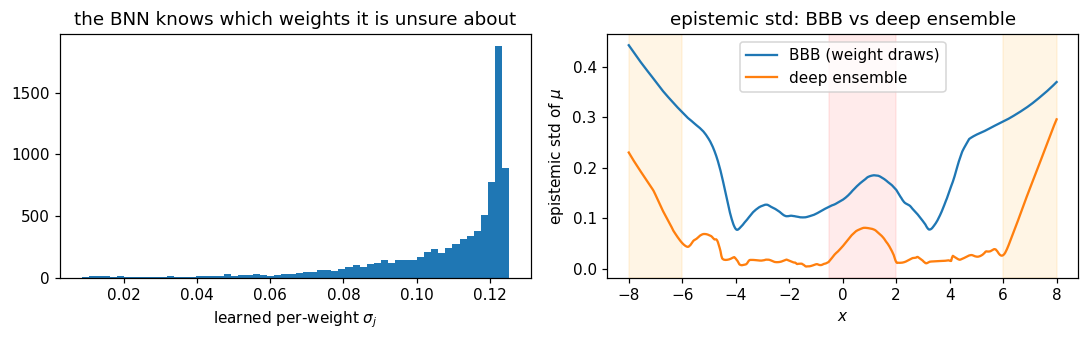

In [9]:
def sample_plain_net(bnn):
    """Draw ONE weight set from q(w) and return an ordinary deterministic MLP carrying it."""
    net = mlp(bnn.layers[0].w_mu.shape[1], bnn.layers[-1].w_mu.shape[0])
    with torch.no_grad():
        for l, m in zip(bnn.layers, [m for m in net if isinstance(m, nn.Linear)]):
            w_s, b_s = l.sigmas()
            m.weight.copy_(l.w_mu + w_s * torch.randn_like(w_s))    # <- forward with replaced weights
            m.bias.copy_(l.b_mu + b_s * torch.randn_like(b_s))
    return net

nets  = [sample_plain_net(bnn) for _ in range(30)]
mus_f = np.stack([hetero_predict(m, xg)[0] for m in nets])          # (30, len(xg))
mus_e = np.stack([hetero_predict(m, xg)[0] for m in members])       # deep ensemble of Part 5

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
all_sig = torch.cat([l.sigmas()[0].flatten() for l in bnn.layers]).detach().numpy()
ax[0].hist(all_sig, bins=60)
ax[0].set(xlabel=r"learned per-weight $\sigma_j$", title="the BNN knows which weights it is unsure about")
ax[1].plot(xg, mus_f.std(0), label="BBB (weight draws)")
ax[1].plot(xg, mus_e.std(0), label="deep ensemble")
shade_regions(ax[1]); ax[1].legend()
ax[1].set(xlabel="$x$", ylabel=r"epistemic std of $\mu$", title="epistemic std: BBB vs deep ensemble")
plt.tight_layout()

## 6b. Post-hoc epistemic: Laplace from scratch, last layer and Kronecker *(worked)*

The free lunch of the lecture: take the **already-trained** heteroscedastic net and add epistemic uncertainty *after the fact*, with no retraining. Laplace replaces the posterior by a Gaussian around the trained weights $\hat w$,
$$\log p(w \mid \mathcal{D}) \approx \log p(\hat w \mid \mathcal{D}) - \tfrac{1}{2}(w - \hat w)^\top H\,(w - \hat w)
\quad\Rightarrow\quad p(w \mid \mathcal{D}) \approx \mathcal{N}(\hat w,\, H^{-1}),$$
with the Hessian in the **generalized Gauss-Newton** form of the lecture:
$$H \approx \sum_{i=1}^{N} J_i^\top \Lambda_i\, J_i + \frac{I}{\sigma_p^2},\qquad
J_i = \frac{\partial f_w(x_i)}{\partial w}\ \text{(network jacobian)},\qquad
\Lambda_i = \frac{1}{\sigma^2(x_i)}\ \text{(output-space curvature, Gaussian regression)}.$$
Here $f_w$ is the mean $\mu(x)$ (one output, $o=1$) and $\sigma(x_i)$ is the net's own learned noise. Linearising the network around $\hat w$ turns the weight covariance into the epistemic band:
$$\sigma^2_{\rm epi}(x) = J(x)\, H^{-1} J(x)^\top .$$

$H$ is $d \times d$ — $d = 8578$ for this small MLP, millions for a real one — so in practice it is never built in full. The code below implements the two standard ways out:

1. **Last layer only.** Take $w$ = the weights of the last linear layer and keep everything before it frozen. Then $J_i = [\phi(x_i), 1]$ is just the penultimate features and $H$ is small enough to build and invert exactly. Two readings worth saying out loud:
   - with a linear last layer this is exact **Bayesian linear regression on the frozen features** — $H^{-1}$ is large along feature directions the data never pinned down, "**how flat is the minimum**", restricted to the last layer;
   - $k(x,x') = \phi(x)^\top H^{-1} \phi(x')$ is a **kernel**, so last-layer Laplace *is* the GP of Part 7 with the kernel *learned* by the network instead of chosen by hand. Same math, one panel apart in the money plot — compare them there.
2. **Kronecker factorisation (KFAC).** Keep *all* the layers, but approximate. For a linear layer $s = W a$ the jacobian is a Kronecker product, $J_i = g_i \otimes a_i$ with $a_i$ the layer input and $g_i = \partial\mu(x_i)/\partial s$, so each term of the sum is one too: $J_i^\top \Lambda_i J_i = \Lambda_i\, g_i g_i^\top \otimes a_i a_i^\top$. KFAC replaces the *sum of Kronecker products* by the *Kronecker product of the sums*,
$$H_\ell \approx G_\ell \otimes A_\ell,\qquad G_\ell = \sum_i \Lambda_i\, g_i g_i^\top,\qquad A_\ell = \frac{1}{N}\sum_i a_i a_i^\top,$$
and treats the layers as independent (block-diagonal $H$). A layer with a $64 \times 65$ weight matrix needs $64^2 + 65^2$ numbers instead of $(64\cdot 65)^2$, and $H^{-1}$ comes from the eigen-decompositions of the two small factors.

What to look at in the third panel. On the **same** layer, the Kronecker curve stays close to the full GGN one: the factorisation itself costs little here. Going from the last layer to **all layers** is the big change: the band opens much more in the gap and in the sidebands, and it also grows inside the trained region. It has steps, because the jacobian of a ReLU network jumps every time a unit switches on or off. How wide it is depends directly on `prior_var`, the one knob that nothing in this cell tunes — change it and watch.

The take-home for the last-layer band is the dependence on the features: **one mode, frozen features — the epistemic band is whatever the learned representation's extrapolation says, with no mechanism to correct it.** On this toy the features fan out generously and the last-layer band in the gap is actually wider and better-covering than the ensemble's; on other problems (try the response-map toy) the same construction is stingier. The ensemble at least lets independently-learned representations disagree.

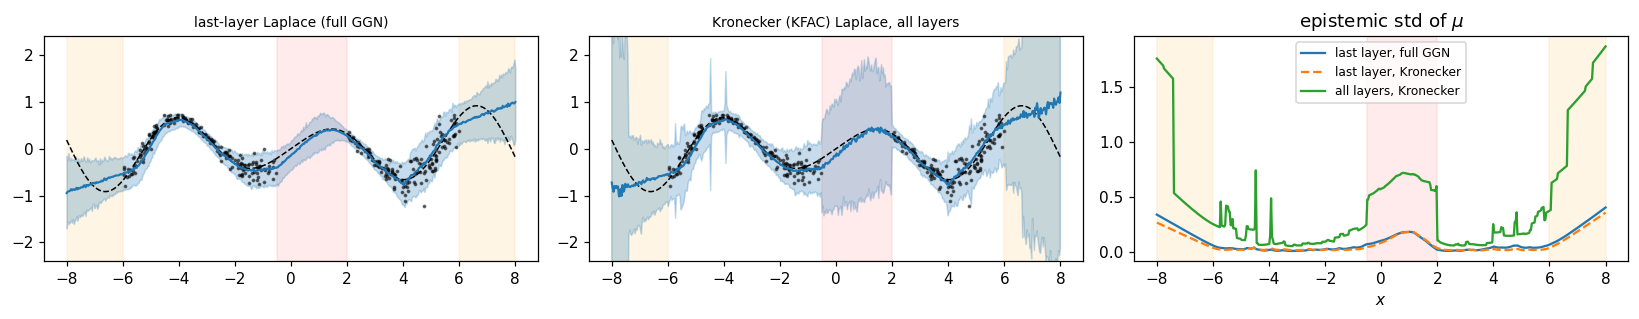

In [9]:
def ggn_jacobian(model, x, params):
    """The network jacobian of the slide: J[i] = d mu(x_i) / d w.

    The output f_w of the slide is the mean mu only (o = 1 output), so each J_i is one row.

    model   : trained net, outputs (mu, raw sigma)
    x       : (n,) points
    params  : list of the tensors that make up w (a subset of model.parameters())
    returns : J, shape (n, d), with d = total number of elements in params
    """
    rows = []
    # one forward + backward pass per point, fine for a few thousand points; torch.func (vmap + jacrev) if it gets slow
    for xi in torch.as_tensor(x)[:, None, None]:             # xi has shape (1, 1): a batch of one point
        # model(xi)[0, 0] is the scalar mu(x_i). autograd.grad returns one gradient tensor per entry
        # of params, each with the shape of that parameter.
        grads = torch.autograd.grad(model(xi)[0, 0], params)
        # Flatten each gradient and join them: one row of J, length d.
        rows.append(torch.cat([g.flatten() for g in grads]))
    # float64: H is inverted later, and float32 is not accurate enough for that.
    return torch.stack(rows).double().numpy()


def ll_laplace(model, x_fit, x_eval, prior_var=1.0):
    """Last-layer Laplace with the full GGN:  H = sum_i J_i^T Lambda_i J_i + I / prior_var.

    Only the last linear layer is uncertain; all the layers before it are frozen.
    H is small (d = 130 here), so it is built and inverted exactly.

    model     : trained heteroscedastic net
    x_fit     : (N,) training points, they build H
    x_eval    : (n,) points where we want the prediction
    prior_var : variance sigma_p^2 of the Gaussian prior on the weights
    returns   : mean (n,), total sigma (n,), epistemic sigma (n,)
    """
    # STEP 1 - choose w. model[-1] is the last nn.Linear: weight (2, hidden) a
    # The row of the sigma output is included too, but mu does not depend on i
    params = list(model[-1].parameters())                  # w = weights and b

    # STEP 2 - jacobian at the training points. For the last layer this is [ph
    # the penultimate features and a 1 for the bias.
    J = ggn_jacobian(model, x_fit, params)                 # (N, d)

    # STEP 3 - Lambda_i = -d^2 log p(y_i | f) / d f^2. For a Gaussian likelihood this is 1 / sigma_i^2.
    # sigma_i is the noise that the net learned itself; it is used as a fixed
    _, sig_fit = hetero_predict(model, x_fit)
    Lam = 1 / sig_fit ** 2                                 # output-space curvature, Gaussian regression

    # STEP 4 - the GGN Hessian of the slide, shape (d, d).
    # Lam[:, None] * J multiplies row i of J by Lambda_i; J.T @ (...) then doe
    # The prior term I / sigma_p^2 keeps H invertible in the directions that the data do not constrain.
    H = J.T @ (Lam[:, None] * J) + np.eye(J.shape[1]) / prior_var

    # STEP 5 - the covariance of the Gaussian that approximates the posterior.
    Sigma = np.linalg.inv(H)                               # Laplace posterior: w ~ N(w_hat, H^-1)

    # STEP 6 - epistemic std at the evaluation points. Linearise the net around w_hat:
    #     mu_w(x) ~ mu_w_hat(x) + J(x) (w - w_hat)   =>   var[mu(x)] = J(x) Si
    # The einsum computes this for each row n, without the full (n, n) matrix.
    J_e = ggn_jacobian(model, x_eval, params)
    epi = np.sqrt(np.einsum("ni,ij,nj->n", J_e, Sigma, J_e))   # linearised ne)^T

    # STEP 7 - mean and aleatoric sigma come from the trained net, unchanged (
    # The two sources are independent, so the variances add.
    mu_e, sig_e = hetero_predict(model, x_eval)
    return mu_e, np.sqrt(epi ** 2 + sig_e ** 2), epi       # mean, total (epi


def layer_io(model, x):
    """The two ingredients of the Kronecker factorisation, for every linear la

        a_i : the input of the layer for point i, with a 1 appended for the bi
        g_i : d mu(x_i) / d s, the gradient of the mean w.r.t. the layer outpu

    The jacobian of the layer is their Kronecker product, J_i = g_i (x) a_i, b
    d mu / d W[j, k] = (d mu / d s[j]) * a[k].

    returns : list with one (a, g) pair per linear layer; a is (n, in + 1), g
    """
    h, a, s = torch.as_tensor(x)[:, None], [], []
    # Forward pass by hand through the nn.Sequential, to record what goes into
    for layer in model:
        if isinstance(layer, nn.Linear): a.append(h)       # input of the linear layer
        h = layer(h)
        if isinstance(layer, nn.Linear): s.append(h)       # output of the lin
    # h[:, 0] is mu for every point. Point i depends only on its own row of each s, so the gradient
    # of the SUM gives d mu_i / d s_i in row i: all the g_i with one backward
    g = torch.autograd.grad(h[:, 0].sum(), s)              # points are independent: one backward gives every g_i
    one = lambda t: torch.cat([t, torch.ones(len(t), 1)], 1)   # append the bi
    return [(one(ai).detach().double().numpy(), gi.double().numpy()) for ai, g


def kron_laplace(model, x_fit, x_eval, prior_var=1.0, last_only=False):
    """Kronecker-factored (KFAC) Laplace: the block of H of each layer is G (xnt.

    Exact GGN block of one layer:   sum_i Lambda_i (g_i g_i^T) (x) (a_i a_i^T)
    KFAC approximation:             [sum_i Lambda_i g_i g_i^T] (x) [mean_i a_i

    last_only : if True, use only the last layer (same weights as ll_laplace)
    returns   : mean (n,), total sigma (n,), epistemic sigma (n,)
    """
    _, sig_fit = hetero_predict(model, x_fit)
    Lam = 1 / sig_fit ** 2                                 # same Lambda_i as in ll_laplace
    io_fit, io_eval = layer_io(model, x_fit), layer_io(model, x_eval)
    if last_only: io_fit, io_eval = io_fit[-1:], io_eval[-1:]

    var = 0.0
    # H is block-diagonal (one block per layer), so the epistemic VARIANCES of
    for (a, g), (a_e, g_e) in zip(io_fit, io_eval):        # (a, g): training points, (a_e, g_e): evaluation points
        A = a.T @ a / len(a)                               # (in+1, in+1): secs
        G = g.T @ (Lam[:, None] * g)                       # (out, out):   sum_i Lambda_i g_i g_i^T

        # Eigen-decompositions of the two SMALL symmetric factors: A = Ua diag(la) Ua^T, G = Ug diag(lg) Ug^T.
        la, Ua = np.linalg.eigh(A); lg, Ug = np.linalg.eigh(G)

        # G (x) A + I / prior_var is diagonal in the basis Ug (x) Ua, with eigior_var:
        # J(x) H^-1 J(x)^T needs only the two small eigen-decompositions, neve
        #   g_e @ Ug, a_e @ Ua : g(x) and a(x) in the two eigen-bases, so J(x)j * a~_k
        #   np.outer(lg, la)   : (out, in+1) table of the eigenvalues of G (x)
        #   einsum             : sum_jk (g~_j * a~_k)^2 / (lg_j * la_k + 1 / prior_var), for each point n
        var = var + np.einsum("nj,jk,nk->n", (g_e @ Ug) ** 2, 1 / (np.outer(lg@ Ua) ** 2)

    # As in ll_laplace: mean and aleatoric sigma from the net, sum in quadrature.
    mu_e, sig_e = hetero_predict(model, x_eval)
    epi = np.sqrt(var)
    return mu_e, np.sqrt(epi ** 2 + sig_e ** 2), epi

mu_la, tot_la, _ = ll_laplace(het, x_tr, x_te)
METHODS["last-layer Laplace"] = gaussian_samples(mu_la, tot_la)
mu_lg, tot_lg, epi_ll = ll_laplace(het, x_tr, xg)
BANDS["last-layer Laplace"] = gaussian_samples(mu_lg, tot_lg)

mu_kg, tot_kg, epi_k = kron_laplace(het, x_tr, xg)                 # all layers
epi_kl = kron_laplace(het, x_tr, xg, last_only=True)[2]            # same layer as ll_laplace: isolates the Kronecker step

fig, ax = plt.subplots(1, 3, figsize=(15, 3))
band_plot(BANDS["last-layer Laplace"], "last-layer Laplace (full GGN)", ax=ax[0])
band_plot(gaussian_samples(mu_kg, tot_kg), "Kronecker (KFAC) Laplace, all layers", ax=ax[1])
ax[2].plot(xg, epi_ll, label="last layer, full GGN")
ax[2].plot(xg, epi_kl, "--", label="last layer, Kronecker")
ax[2].plot(xg, epi_k, label="all layers, Kronecker")
shade_regions(ax[2]); ax[2].legend(fontsize=8)
ax[2].set(xlabel="$x$", title=r"epistemic std of $\mu$")
plt.tight_layout()

## 7. The reference: an exact Gaussian process *(worked)*

In 1D with 300 points we can afford **exact function-space Bayes**: a GP with an RBF kernel and the *known* aleatoric noise $\sigma^2(x_i)$ on the diagonal. Its posterior variance is what correct epistemic uncertainty looks like — growing smoothly away from the data, collapsing onto it — and every neural method above is an approximation to something like this. Fifteen lines of numpy:

One thing to stare at in the sidebands: the GP is the only method whose extrapolation statement is *explicit* — beyond the data it reverts to its prior (mean 0, full prior variance). Whether that is the right answer depends on whether the prior is; but at least you know what was assumed.

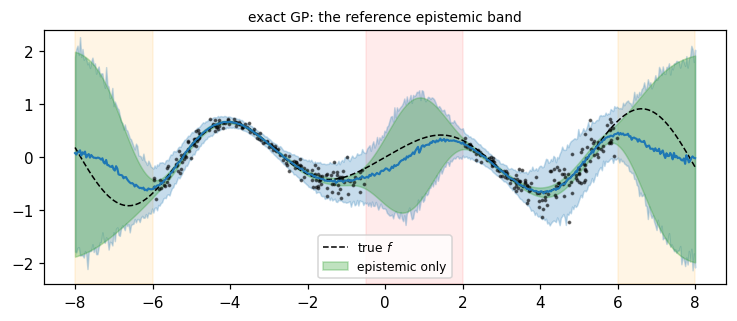

In [10]:
def rbf(a, b, ell=1.0, amp=1.0):
    return amp**2 * np.exp(-0.5 * (a[:, None] - b[None, :])**2 / ell**2)

def gp_posterior(x_tr, y_tr, x_new, ell=1.0, amp=1.0):
    K   = rbf(x_tr, x_tr, ell, amp) + np.diag(sigma_true(x_tr)**2) + 1e-8 * np.eye(len(x_tr))
    Ks  = rbf(x_new, x_tr, ell, amp)
    Kss = rbf(x_new, x_new, ell, amp)
    L = np.linalg.cholesky(K)
    alpha = np.linalg.solve(L.T, np.linalg.solve(L, y_tr))
    mean = Ks @ alpha
    v = np.linalg.solve(L, Ks.T)
    var_epi = np.clip(np.diag(Kss) - (v**2).sum(axis=0), 0, None)
    return mean, np.sqrt(var_epi)

def gp_samples(x, S=400):
    m, s_epi = gp_posterior(x_tr, y_tr, x)
    s_tot = np.sqrt(s_epi**2 + sigma_true(x)**2)          # + known aleatoric
    return m[:, None] + s_tot[:, None] * rng.standard_normal((len(x), S))

METHODS["exact GP"] = gp_samples(x_te)
BANDS["exact GP"]   = gp_samples(xg)
ax = band_plot(BANDS["exact GP"], "exact GP: the reference epistemic band")
m, s_epi = gp_posterior(x_tr, y_tr, xg)
ax.fill_between(xg, m - 2*s_epi, m + 2*s_epi, color="C2", alpha=0.3, label="epistemic only")
ax.legend(fontsize=8);

**Discussion + EXERCISES:** 

(a) change the lengthscale `ell` to 0.3 and 3.0 — the epistemic band is only "correct" *given* the kernel: the prior matters here exactly as it does for BNNs.

(b) Why don't we just use a GP in the calorimeter notebook, or in real analyses? (exact cost $O(n^3)$, and in high dimensions a generic kernel is a worse inductive bias than a trained network — this is the honest answer to "why neural networks at all"). 

(c) Infinite-width connection: an infinitely wide BNN with scaled Gaussian priors *is* a GP (Neal 1996) — sample functions from the untrained `BNN` above with growing `hidden` and test that they become GP-like.

## 8. The money plot: all bands side by side

This is the figure the whole warm-up builds toward. Same data, same axes, six answers to "what do you know about $f$?".

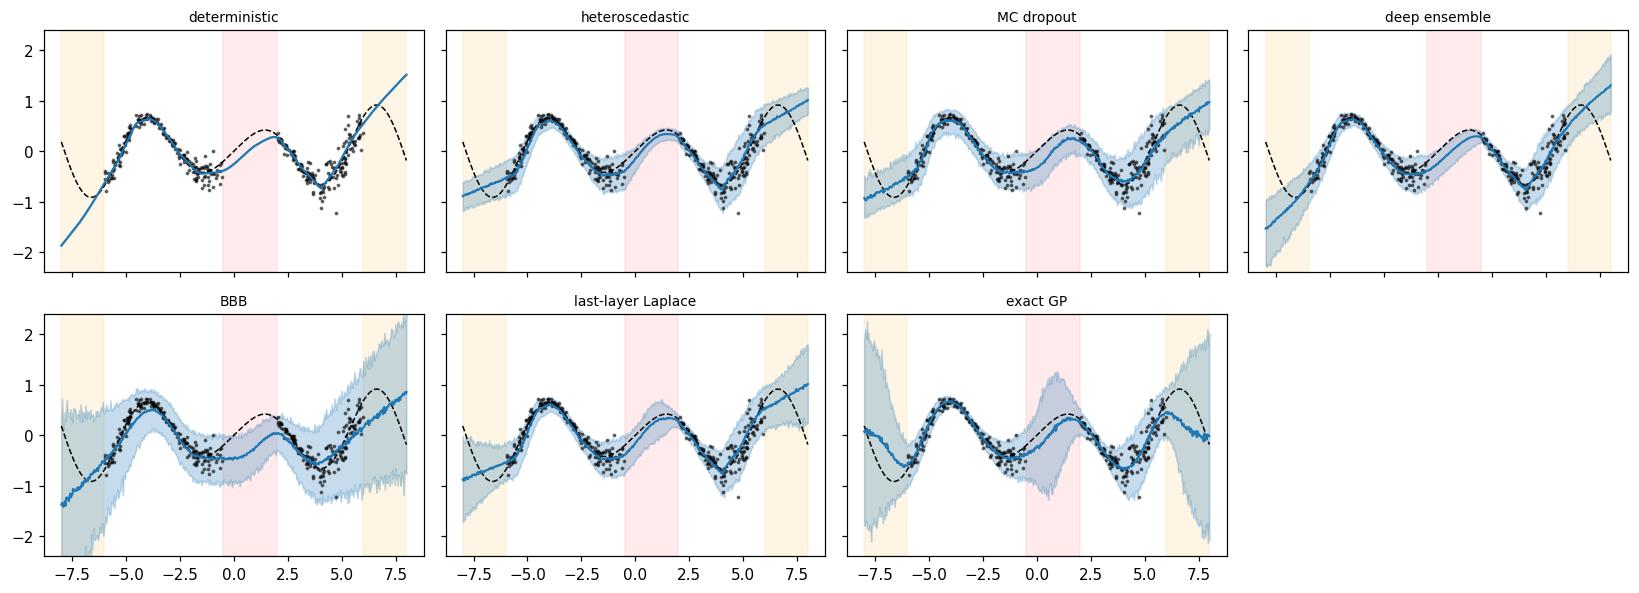

In [11]:
names = ["deterministic", "heteroscedastic", "MC dropout", "deep ensemble",
         "BBB", "last-layer Laplace", "exact GP"]
fig, axes = plt.subplots(2, 4, figsize=(15, 5.5), sharex=True, sharey=True)
for name, ax in zip(names, axes.ravel()):
    band_plot(BANDS[name], name, ax=ax)
axes.ravel()[-1].axis("off")
plt.tight_layout()

## 9. Numbers to go with the pictures

The scoreboard on the full range, then separately for the **gap** (interpolation) and the **sidebands** (extrapolation). Expect the two regimes to rank methods differently: in the gap, smoothness carries everyone part of the way; in the sidebands, methods diverge — the GP reverts to its prior (honest, wide), ensembles fan out as far as their learned functions happen to disagree, single networks invent a confident continuation. The ranking by CRPS should match your visual ranking of the bands — this is the point where you can start trusting the numbers, which is all you will have in the calorimeter notebook.

method                 CRPS   cov68  width68   cov95  width95
deterministic        0.2757   0.004   0.0020   0.006   0.0038


heteroscedastic      0.1620   0.465   0.2814   0.747   0.5507
MC dropout           0.1694   0.589   0.3840   0.816   0.7634


deep ensemble        0.1910   0.524   0.3392   0.765   0.6509
BBB                  0.2226   0.708   0.7858   0.899   1.6207


last-layer Laplace   0.1504   0.542   0.3691   0.859   0.7231
exact GP             0.1568   0.695   0.6273   0.952   1.2273

--- gap (interpolation) ---
method                 CRPS   cov68  width68   cov95  width95
deterministic        0.2545   0.002   0.0020   0.003   0.0038
heteroscedastic      0.1501   0.263   0.1742   0.508   0.3411


MC dropout           0.2121   0.306   0.3227   0.593   0.6418
deep ensemble        0.1868   0.295   0.2528   0.497   0.4670
BBB                  0.3999   0.100   0.4374   0.380   0.9053
last-layer Laplace   0.1359   0.496   0.3238   0.818   0.6348
exact GP             0.1652   0.817   0.7886   0.987   1.5435

--- sidebands (extrapolation) ---
method                 CRPS   cov68  width68   cov95  width95
deterministic        0.6443   0.000   0.0020   0.001   0.0038
heteroscedastic      0.3198   0.274   0.3182   0.513   0.6222
MC dropout           0.3170   0.315   0.4450   0.610   0.8823


deep ensemble        0.4305   0.353   0.5242   0.564   0.9821
BBB                  0.3379   0.725   1.3237   0.991   2.7965
last-layer Laplace   0.2827   0.413   0.5623   0.754   1.1008
exact GP             0.3128   0.666   1.2961   0.958   2.5360


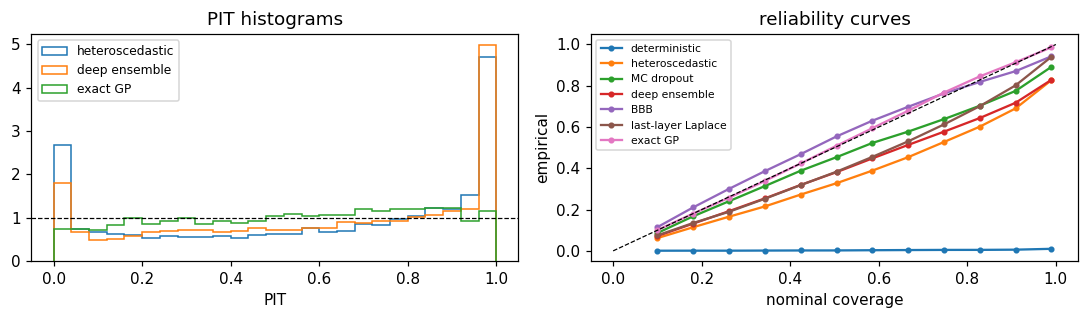

In [12]:
scoreboard(y_te, METHODS)
gap_mask = (x_te > GAP[0]) & (x_te < GAP[1])
extrap_mask = np.abs(x_te) > SIDE
print("\n--- gap (interpolation) ---")
scoreboard(y_te[gap_mask], {k: v[gap_mask] for k, v in METHODS.items()})
print("\n--- sidebands (extrapolation) ---")
scoreboard(y_te[extrap_mask], {k: v[extrap_mask] for k, v in METHODS.items()})

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for name in ("heteroscedastic", "deep ensemble", "exact GP"):
    ax[0].hist(pit_values(y_te, METHODS[name]), bins=25, density=True, histtype="step", label=name)
ax[0].axhline(1, ls="--", c="k", lw=0.8); ax[0].set(xlabel="PIT", title="PIT histograms"); ax[0].legend(fontsize=8)
levels = np.linspace(0.1, 0.99, 12)
for name in names:
    ax[1].plot(levels, [central_coverage(y_te, METHODS[name], l)[0] for l in levels], "o-", ms=3, label=name)
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[1].set(xlabel="nominal coverage", ylabel="empirical", title="reliability curves"); ax[1].legend(fontsize=7)
plt.tight_layout()

## 11. Where to next

Everything here transfers unchanged to the calorimeter notebook: same toolbox, same methods. Added an asymmetric-tail failure of the Gaussian head.  
The one thing that does *not* transfer is this notebook's luxury: being able to **look** at the answer. From here on, the PIT histogram, the reliability curve and the proper scores *are* your eyes.